## Building and Comparing RNN, LSTM, GRU, and Bi-LSTM Models for News Topic Classification

In [3]:
%pip install -q tensorflow datasets scikit-learn pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [4]:
!pip install datasets

In [5]:
import os
import time
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    SimpleRNN,
    LSTM,
    GRU,
    Bidirectional,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

warnings.filterwarnings("ignore")


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


MAX_WORDS = 20000
MAX_LEN = 100
EMBEDDING_DIM = 64
HIDDEN_UNITS = 64
BATCH_SIZE = 256
EPOCHS = 5
NUM_CLASSES = 4

CLASS_NAMES = ["World", "Sports", "Business", "Sci/Tech"]

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)
print("Configuration completed successfully.")

TensorFlow version: 2.21.0
GPU available: False
Configuration completed successfully.


## Task 1: Loading and Exploring the Dataset

Note: you may need to restart the kernel to use updated packages.
Loading AG News dataset...



DATASET STRUCTURE
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

TRAINING SAMPLES: 120000
TEST SAMPLES: 7600

TRAINING DATA SHAPE: (120000, 2)
TEST DATA SHAPE: (7600, 2)

COLUMN NAMES
['text', 'label']

FIVE SAMPLE NEWS ARTICLES

Article 1
Text: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
Label: 2
Category: Business

Article 2
Text: Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial plays in the defense industry, has quietly placed\its bets on another part of the market.
Label: 2
Category: Business

Article 3
Text: Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the e

,Category,Number of Articles
0,World,30000
1,Sports,30000
2,Business,30000
3,Sci/Tech,30000


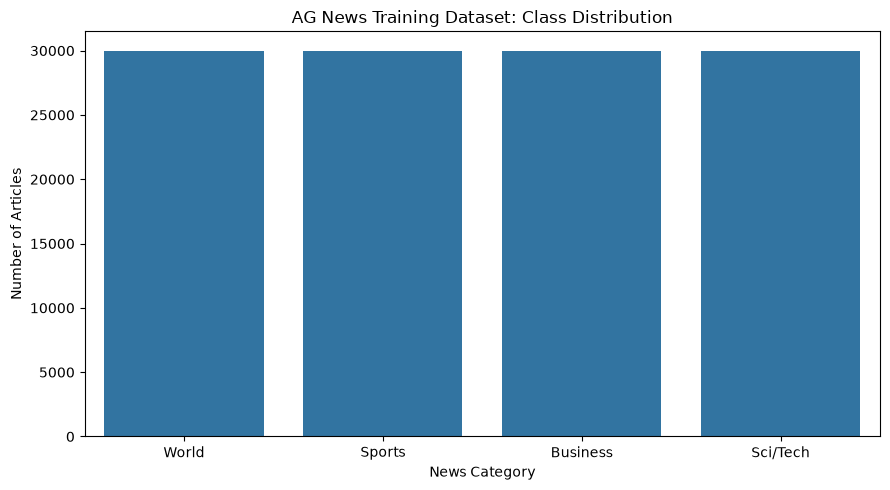


Dataset loaded and explored successfully!


In [6]:
%pip install -q -U datasets huggingface_hub pandas matplotlib seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset


CLASS_NAMES = ["World", "Sports", "Business", "Sci/Tech"]


print("Loading AG News dataset...")

dataset = load_dataset("fancyzhx/ag_news")

print("\nDATASET STRUCTURE")
print(dataset)


train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("\nTRAINING SAMPLES:", len(train_df))
print("TEST SAMPLES:", len(test_df))

print("\nTRAINING DATA SHAPE:", train_df.shape)
print("TEST DATA SHAPE:", test_df.shape)

print("\nCOLUMN NAMES")
print(train_df.columns.tolist())


print("\nFIVE SAMPLE NEWS ARTICLES")

for i, row in train_df.head(5).iterrows():
    print(f"\nArticle {i + 1}")
    print("Text:", row["text"])
    print("Label:", row["label"])
    print("Category:", CLASS_NAMES[int(row["label"])])


class_distribution = (
    train_df["label"]
    .value_counts()
    .sort_index()
)

distribution_df = pd.DataFrame({
    "Category": CLASS_NAMES,
    "Number of Articles": [
        int(class_distribution.get(i, 0))
        for i in range(4)
    ]
})

print("\nCLASS DISTRIBUTION")
display(distribution_df)


plt.figure(figsize=(9, 5))

sns.barplot(
    data=distribution_df,
    x="Category",
    y="Number of Articles"
)

plt.title("AG News Training Dataset: Class Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")

plt.tight_layout()
plt.show()

print("\nDataset loaded and explored successfully!")

## Task 2: Text Preprocessing

In [ ]:
##Importing required libraries

In [7]:
import os
import time
import random
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    SimpleRNN,
    LSTM,
    GRU,
    Bidirectional,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Libraries imported successfully.")
print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

Libraries imported successfully.
TensorFlow version: 2.21.0
GPU available: False


In [ ]:
## Configuring preprocessing

In [8]:
MAX_WORDS = 20000
MAX_LEN = 100
EMBEDDING_DIM = 64
HIDDEN_UNITS = 64
BATCH_SIZE = 256
EPOCHS = 5
NUM_CLASSES = 4

CLASS_NAMES = ["World", "Sports", "Business", "Sci/Tech"]

print("Maximum vocabulary:", MAX_WORDS)
print("Maximum sequence length:", MAX_LEN)
print("Embedding dimension:", EMBEDDING_DIM)
print("Hidden units:", HIDDEN_UNITS)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", EPOCHS)

Maximum vocabulary: 20000
Maximum sequence length: 100
Embedding dimension: 64
Hidden units: 64
Batch size: 256
Maximum epochs: 5


In [ ]:
## Extracting text and labels

In [9]:
import numpy as np
from sklearn.model_selection import train_test_split


X_text = train_df["text"].astype(str).to_numpy()
y = train_df["label"].to_numpy(dtype=np.int32)

X_test_text = test_df["text"].astype(str).to_numpy()
y_test = test_df["label"].to_numpy(dtype=np.int32)

# Split training data into training and validation sets
X_train_text, X_val_text, y_train, y_val = train_test_split(
    X_text,
    y,
    test_size=0.10,
    random_state=42,
    stratify=y
)


print("Training samples:", len(X_train_text))
print("Validation samples:", len(X_val_text))
print("Test samples:", len(X_test_text))


assert len(X_train_text) == len(y_train)
assert len(X_val_text) == len(y_val)
assert len(X_test_text) == len(y_test)

print("\nData extraction and splitting completed successfully!")

Training samples: 108000
Validation samples: 12000
Test samples: 7600

Data extraction and splitting completed successfully!


In [ ]:
## Tokenization

In [10]:
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

# Learn vocabulary using training text only
tokenizer.fit_on_texts(X_train_text)

# Convert text into numerical sequences
X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_val_seq = tokenizer.texts_to_sequences(X_val_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

VOCAB_SIZE = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

print("Vocabulary size:", VOCAB_SIZE)

print("\nOriginal article:")
print(X_train_text[0][:300])

print("\nTokenized article:")
print(X_train_seq[0][:30])

Vocabulary size: 20000

Original article:
10 seconds that change everything ATHENS - Ten seconds. Barely time enough to tie a shoe, wash a glass, get the paper off the porch. But when the moment comes, and eight men kneel at their blocks and peer down the empty, waiting track, it is as if the entire Olympics stop to watch.

Tokenized article:
[132, 1780, 12, 680, 2622, 372, 1845, 1780, 3692, 82, 856, 3, 1682, 4, 7690, 5350, 4, 5861, 224, 2, 2424, 102, 2, 18920, 44, 88, 2, 2820, 1139, 7]


In [ ]:
## Padding and truncation

In [11]:
X_train = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training data shape:", X_train.shape)
print("Validation data shape:", X_val.shape)
print("Test data shape:", X_test.shape)

print("Training labels shape:", y_train.shape)
print("Validation labels shape:", y_val.shape)
print("Test labels shape:", y_test.shape)

print("\nPreprocessing completed successfully.")

Training data shape: (108000, 100)
Validation data shape: (12000, 100)
Test data shape: (7600, 100)
Training labels shape: (108000,)
Validation labels shape: (12000,)
Test labels shape: (7600,)

Preprocessing completed successfully.


In [ ]:
## Validating preprocessing

In [12]:
assert X_train.shape[1] == MAX_LEN
assert X_val.shape[1] == MAX_LEN
assert X_test.shape[1] == MAX_LEN

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

assert np.all((y_train >= 0) & (y_train < NUM_CLASSES))
assert np.all((y_val >= 0) & (y_val < NUM_CLASSES))
assert np.all((y_test >= 0) & (y_test < NUM_CLASSES))

print("All preprocessing checks passed.")

All preprocessing checks passed.


## STEP 3 — Building and Training a Simple RNN

In [ ]:
## Building the Simple RNN model

In [13]:
def build_simple_rnn(clipnorm=None):

    model = Sequential([
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
            mask_zero=True
        ),

        SimpleRNN(HIDDEN_UNITS),

        Dense(64, activation="relu"),

        Dropout(0.3),

        Dense(NUM_CLASSES, activation="softmax")
    ], name="Simple_RNN")

    optimizer = Adam(
        learning_rate=0.001,
        clipnorm=clipnorm
    )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


rnn_model = build_simple_rnn()

rnn_model.summary()

Model: "Simple_RNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn (SimpleRNN)               │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
## Training Simple RNN

In [14]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

start_time = time.time()

rnn_history = rnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=1
)

rnn_training_time = time.time() - start_time

print(f"Training time: {rnn_training_time:.2f} seconds")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 24s 52ms/step - accuracy: 0.8225 - loss: 0.4760 - val_accuracy: 0.9067 - val_loss: 0.2966
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 23s 54ms/step - accuracy: 0.9172 - loss: 0.2677 - val_accuracy: 0.9076 - val_loss: 0.2972
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 53ms/step - accuracy: 0.9365 - loss: 0.2076 - val_accuracy: 0.9019 - val_loss: 0.3391
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.
Training time: 87.86 seconds


In [ ]:
## Evaluating the Simple RNN

In [15]:
rnn_test_loss, rnn_test_accuracy = rnn_model.evaluate(
    X_test,
    y_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

rnn_train_accuracy = max(rnn_history.history["accuracy"])

rnn_val_accuracy = max(rnn_history.history["val_accuracy"])

print("SIMPLE RNN RESULTS")
print("-" * 40)
print(f"Best Training Accuracy:   {rnn_train_accuracy:.4f}")
print(f"Best Validation Accuracy: {rnn_val_accuracy:.4f}")
print(f"Test Accuracy:            {rnn_test_accuracy:.4f}")
print(f"Test Loss:                {rnn_test_loss:.4f}")
print(f"Training Time:            {rnn_training_time:.2f} seconds")

SIMPLE RNN RESULTS
----------------------------------------
Best Training Accuracy:   0.9365
Best Validation Accuracy: 0.9076
Test Accuracy:            0.8982
Test Loss:                0.3165
Training Time:            87.86 seconds


In [ ]:
## Plotting Simple RNN learning curves

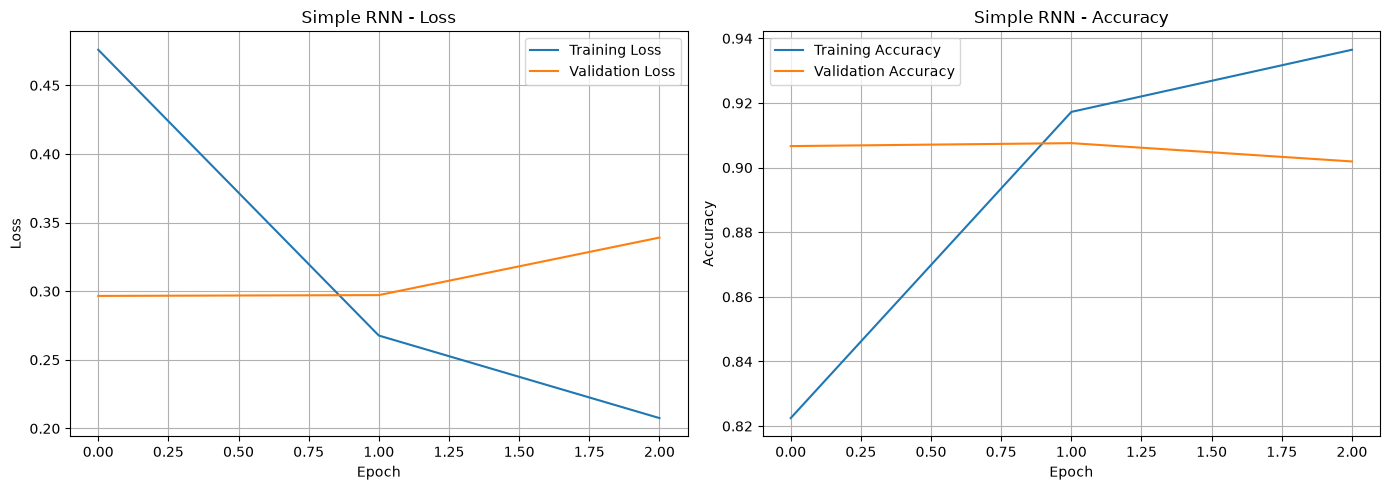

In [16]:
def plot_history(history, model_name):

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Loss
    axes[0].plot(
        history.history["loss"],
        label="Training Loss"
    )

    axes[0].plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    axes[0].set_title(f"{model_name} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True)

    # Accuracy
    axes[1].plot(
        history.history["accuracy"],
        label="Training Accuracy"
    )

    axes[1].plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    axes[1].set_title(f"{model_name} - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()


plot_history(rnn_history, "Simple RNN")

## The Simple RNN establishes the baseline performance for news classification. Compare its training, validation, and test accuracy to determine how effectively it learns category-related information from news articles. A substantial difference between training and validation accuracy may indicate overfitting.

## Task 4 - Building and Training LSTM

In [ ]:
## Building the LSTM model

In [17]:
def build_lstm(clipnorm=None):

    model = Sequential([
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
            mask_zero=True
        ),

        LSTM(HIDDEN_UNITS),

        Dense(64, activation="relu"),

        Dropout(0.3),

        Dense(NUM_CLASSES, activation="softmax")
    ], name="LSTM")

    model.compile(
        optimizer=Adam(
            learning_rate=0.001,
            clipnorm=clipnorm
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


lstm_model = build_lstm()

lstm_model.summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [23]:
## Training LSTM

In [18]:
start_time = time.time()

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True,
            verbose=1
        )
    ],
    verbose=1
)

lstm_training_time = time.time() - start_time

print(f"LSTM training time: {lstm_training_time:.2f} seconds")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 60s 137ms/step - accuracy: 0.8531 - loss: 0.4263 - val_accuracy: 0.9183 - val_loss: 0.2552
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 58s 137ms/step - accuracy: 0.9314 - loss: 0.2222 - val_accuracy: 0.9158 - val_loss: 0.2547
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 58s 136ms/step - accuracy: 0.9443 - loss: 0.1790 - val_accuracy: 0.9134 - val_loss: 0.2795
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 58s 138ms/step - accuracy: 0.9505 - loss: 0.1551 - val_accuracy: 0.9092 - val_loss: 0.3123
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.
LSTM training time: 233.79 seconds


In [ ]:
## Evaluating the LSTM

In [19]:
lstm_test_loss, lstm_test_accuracy = lstm_model.evaluate(
    X_test,
    y_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

lstm_train_accuracy = max(lstm_history.history["accuracy"])
lstm_val_accuracy = max(lstm_history.history["val_accuracy"])

print("LSTM RESULTS")
print("-" * 40)
print(f"Best Training Accuracy:   {lstm_train_accuracy:.4f}")
print(f"Best Validation Accuracy: {lstm_val_accuracy:.4f}")
print(f"Test Accuracy:            {lstm_test_accuracy:.4f}")
print(f"Test Loss:                {lstm_test_loss:.4f}")
print(f"Training Time:            {lstm_training_time:.2f} seconds")

LSTM RESULTS
----------------------------------------
Best Training Accuracy:   0.9505
Best Validation Accuracy: 0.9183
Test Accuracy:            0.9151
Test Loss:                0.2635
Training Time:            233.79 seconds


In [ ]:
## Plotting LSTM curves

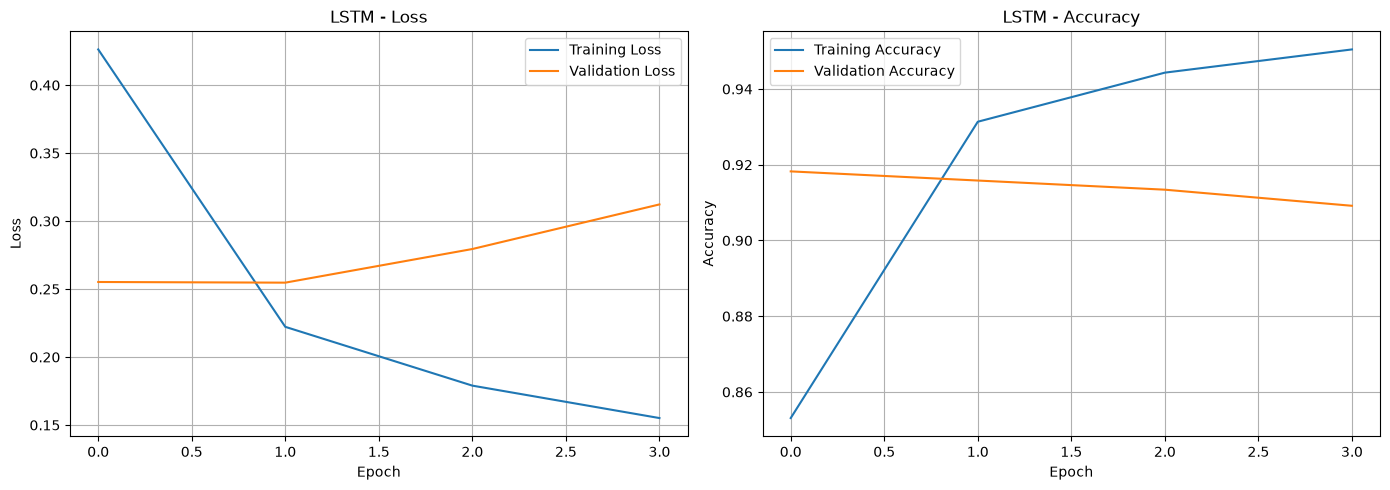

In [20]:
plot_history(lstm_history, "LSTM")

In [19]:
## Comparing Simple RNN and LSTM

In [21]:
print("SIMPLE RNN VS LSTM")
print("-" * 45)

print(f"Simple RNN Test Accuracy: {rnn_test_accuracy:.4f}")
print(f"LSTM Test Accuracy:      {lstm_test_accuracy:.4f}")

difference = (
    lstm_test_accuracy - rnn_test_accuracy
) * 100

print(f"Accuracy Difference:     {difference:.2f} percentage points")

if difference > 0:
    print("LSTM achieved higher test accuracy.")
elif difference < 0:
    print("Simple RNN achieved higher test accuracy.")
else:
    print("Both models achieved equal test accuracy.")

SIMPLE RNN VS LSTM
---------------------------------------------
Simple RNN Test Accuracy: 0.8982
LSTM Test Accuracy:      0.9151
Accuracy Difference:     1.70 percentage points
LSTM achieved higher test accuracy.


## Task 5 - Building and Training a GRU

In [ ]:
## Building the GRU model

In [22]:
def build_gru(clipnorm=None):

    model = Sequential([
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
            mask_zero=True
        ),

        GRU(HIDDEN_UNITS),

        Dense(64, activation="relu"),

        Dropout(0.3),

        Dense(NUM_CLASSES, activation="softmax")
    ], name="GRU")

    model.compile(
        optimizer=Adam(
            learning_rate=0.001,
            clipnorm=clipnorm
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


gru_model = build_gru()

gru_model.summary()

Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru (GRU)                            │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
## Training GRU

In [23]:
start_time = time.time()

gru_history = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True,
            verbose=1
        )
    ],
    verbose=1
)

gru_training_time = time.time() - start_time

print(f"GRU training time: {gru_training_time:.2f} seconds")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - accuracy: 0.8142 - loss: 0.4942 - val_accuracy: 0.9119 - val_loss: 0.2751
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - accuracy: 0.9275 - loss: 0.2372 - val_accuracy: 0.9162 - val_loss: 0.2708
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 107ms/step - accuracy: 0.9418 - loss: 0.1913 - val_accuracy: 0.9144 - val_loss: 0.2788
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 106ms/step - accuracy: 0.9496 - loss: 0.1644 - val_accuracy: 0.9115 - val_loss: 0.2984
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.
GRU training time: 183.94 seconds


In [ ]:
## Evaluating the GRU

In [24]:
gru_test_loss, gru_test_accuracy = gru_model.evaluate(
    X_test,
    y_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

gru_train_accuracy = max(gru_history.history["accuracy"])
gru_val_accuracy = max(gru_history.history["val_accuracy"])

print("GRU RESULTS")
print("-" * 40)
print(f"Best Training Accuracy:   {gru_train_accuracy:.4f}")
print(f"Best Validation Accuracy: {gru_val_accuracy:.4f}")
print(f"Test Accuracy:            {gru_test_accuracy:.4f}")
print(f"Test Loss:                {gru_test_loss:.4f}")
print(f"Training Time:            {gru_training_time:.2f} seconds")

GRU RESULTS
----------------------------------------
Best Training Accuracy:   0.9496
Best Validation Accuracy: 0.9162
Test Accuracy:            0.9129
Test Loss:                0.2792
Training Time:            183.94 seconds


In [ ]:
## Plotting GRU curves

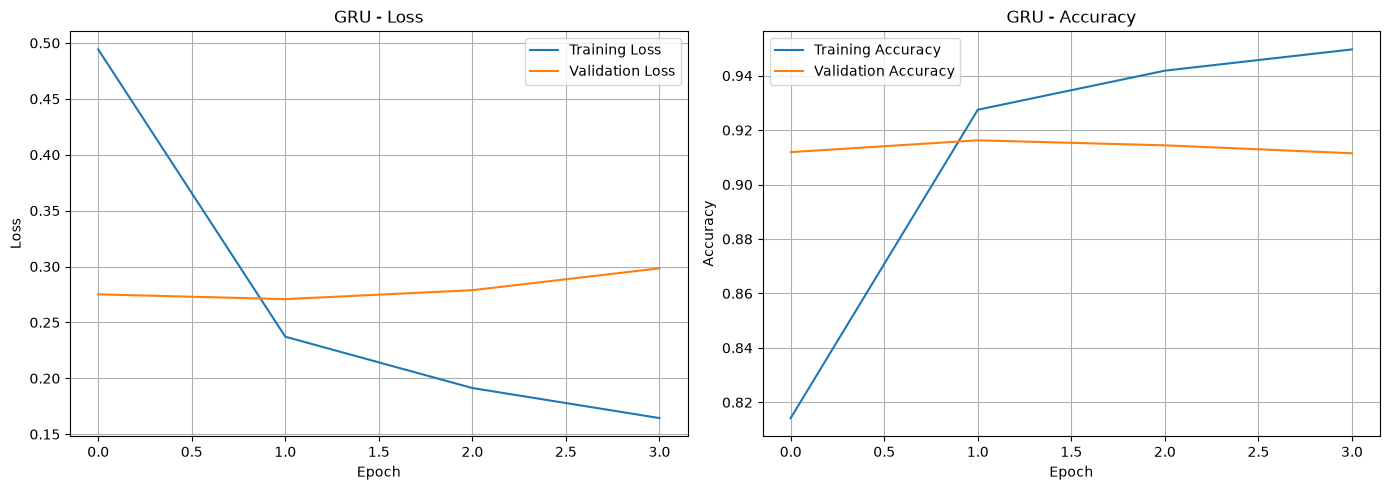

In [25]:
plot_history(gru_history, "GRU")

## Task 6 — Build and Train a Bidirectional LSTM

In [25]:
## Building the Bi-LSTM model

In [26]:
def build_bilstm(clipnorm=None):

    model = Sequential([
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
            mask_zero=True
        ),

        Bidirectional(
            LSTM(HIDDEN_UNITS)
        ),

        Dense(64, activation="relu"),

        Dropout(0.3),

        Dense(NUM_CLASSES, activation="softmax")
    ], name="Bi_LSTM")

    model.compile(
        optimizer=Adam(
            learning_rate=0.001,
            clipnorm=clipnorm
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


bilstm_model = build_bilstm()

bilstm_model.summary()

Model: "Bi_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
## Training the Bi-LSTM

In [27]:
start_time = time.time()

bilstm_history = bilstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True,
            verbose=1
        )
    ],
    verbose=1
)

bilstm_training_time = time.time() - start_time

print(f"Bi-LSTM training time: {bilstm_training_time:.2f} seconds")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 62s 139ms/step - accuracy: 0.8648 - loss: 0.3889 - val_accuracy: 0.9197 - val_loss: 0.2404
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 62s 146ms/step - accuracy: 0.9354 - loss: 0.2016 - val_accuracy: 0.9183 - val_loss: 0.2506
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 63s 148ms/step - accuracy: 0.9469 - loss: 0.1625 - val_accuracy: 0.9133 - val_loss: 0.2674
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.
Bi-LSTM training time: 186.55 seconds


In [ ]:
## Evaluate the Bi-LSTM

In [28]:
bilstm_test_loss, bilstm_test_accuracy = bilstm_model.evaluate(
    X_test,
    y_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

bilstm_train_accuracy = max(bilstm_history.history["accuracy"])
bilstm_val_accuracy = max(bilstm_history.history["val_accuracy"])

print("BI-LSTM RESULTS")
print("-" * 40)
print(f"Best Training Accuracy:   {bilstm_train_accuracy:.4f}")
print(f"Best Validation Accuracy: {bilstm_val_accuracy:.4f}")
print(f"Test Accuracy:            {bilstm_test_accuracy:.4f}")
print(f"Test Loss:                {bilstm_test_loss:.4f}")
print(f"Training Time:            {bilstm_training_time:.2f} seconds")

BI-LSTM RESULTS
----------------------------------------
Best Training Accuracy:   0.9469
Best Validation Accuracy: 0.9197
Test Accuracy:            0.9187
Test Loss:                0.2477
Training Time:            186.55 seconds


## Task 7 — Gradient Clipping

In [ ]:
## Training Simple RNN without gradient clipping

In [29]:
rnn_no_clip = build_simple_rnn(clipnorm=None)

start_time = time.time()

history_no_clip = rnn_no_clip.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True,
            verbose=1
        )
    ],
    verbose=1
)

time_no_clip = time.time() - start_time

loss_no_clip, accuracy_no_clip = rnn_no_clip.evaluate(
    X_test,
    y_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

print("Test accuracy without clipping:", round(accuracy_no_clip, 4))
print("Test loss without clipping:", round(loss_no_clip, 4))
print("Training time:", round(time_no_clip, 2), "seconds")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - accuracy: 0.8215 - loss: 0.4752 - val_accuracy: 0.9072 - val_loss: 0.2941
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 44ms/step - accuracy: 0.9246 - loss: 0.2444 - val_accuracy: 0.9040 - val_loss: 0.2988
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 44ms/step - accuracy: 0.9430 - loss: 0.1837 - val_accuracy: 0.8965 - val_loss: 0.3449
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.
Test accuracy without clipping: 0.9039
Test loss without clipping: 0.3148
Training time: 57.53 seconds


In [ ]:
## Training Simple RNN with gradient clipping

In [30]:
rnn_with_clip = build_simple_rnn(clipnorm=1.0)

start_time = time.time()

history_with_clip = rnn_with_clip.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True,
            verbose=1
        )
    ],
    verbose=1
)

time_with_clip = time.time() - start_time

loss_with_clip, accuracy_with_clip = rnn_with_clip.evaluate(
    X_test,
    y_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

print("Test accuracy with clipping:", round(accuracy_with_clip, 4))
print("Test loss with clipping:", round(loss_with_clip, 4))
print("Training time:", round(time_with_clip, 2), "seconds")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - accuracy: 0.7763 - loss: 0.5491 - val_accuracy: 0.9124 - val_loss: 0.2845
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 44ms/step - accuracy: 0.9214 - loss: 0.2586 - val_accuracy: 0.9144 - val_loss: 0.2808
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 43ms/step - accuracy: 0.9386 - loss: 0.2022 - val_accuracy: 0.9053 - val_loss: 0.3286
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 43ms/step - accuracy: 0.9518 - loss: 0.1534 - val_accuracy: 0.8986 - val_loss: 0.3879
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.
Test accuracy with clipping: 0.9078
Test loss with clipping: 0.2931
Training time: 76.23 seconds


In [ ]:
## Comparing gradient clipping

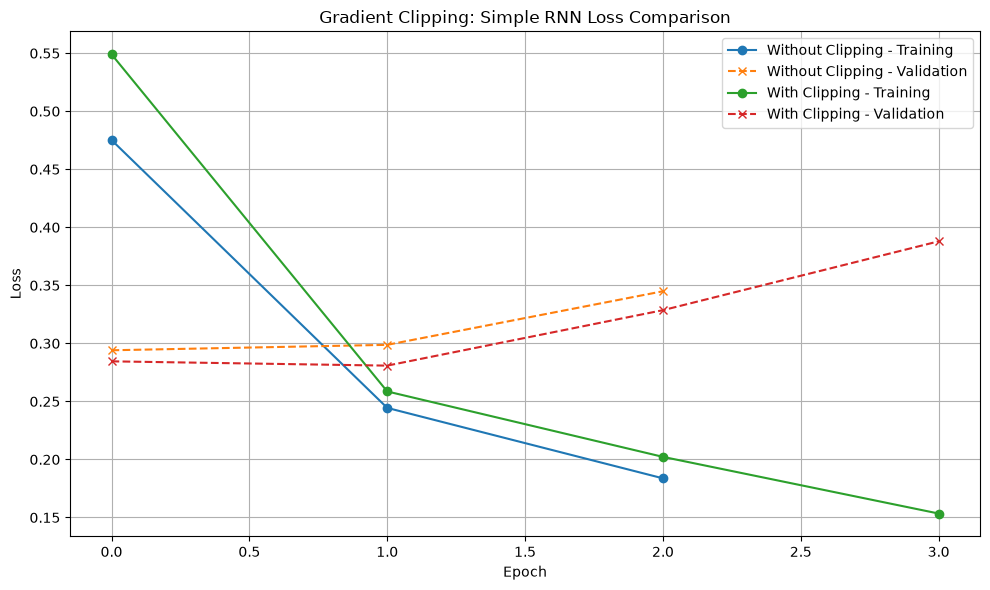

,Configuration,Test Accuracy,Test Loss,Training Time (seconds)
0,Without Gradient Clipping,0.903947,0.314849,57.532569
1,With Gradient Clipping,0.907763,0.293052,76.232031


In [31]:
plt.figure(figsize=(10, 6))

plt.plot(
    history_no_clip.history["loss"],
    marker="o",
    label="Without Clipping - Training"
)

plt.plot(
    history_no_clip.history["val_loss"],
    marker="x",
    linestyle="--",
    label="Without Clipping - Validation"
)

plt.plot(
    history_with_clip.history["loss"],
    marker="o",
    label="With Clipping - Training"
)

plt.plot(
    history_with_clip.history["val_loss"],
    marker="x",
    linestyle="--",
    label="With Clipping - Validation"
)

plt.title("Gradient Clipping: Simple RNN Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


gradient_comparison = pd.DataFrame({
    "Configuration": [
        "Without Gradient Clipping",
        "With Gradient Clipping"
    ],
    "Test Accuracy": [
        accuracy_no_clip,
        accuracy_with_clip
    ],
    "Test Loss": [
        loss_no_clip,
        loss_with_clip
    ],
    "Training Time (seconds)": [
        time_no_clip,
        time_with_clip
    ]
})

display(gradient_comparison)

## Task 8 — Comparing All Four Models

In [ ]:
## Comparison table

In [32]:
comparison_data = [
    {
        "Model": "Simple RNN",
        "Training Accuracy": rnn_train_accuracy,
        "Validation Accuracy": rnn_val_accuracy,
        "Test Accuracy": rnn_test_accuracy,
        "Training Time (seconds)": rnn_training_time
    },
    {
        "Model": "LSTM",
        "Training Accuracy": lstm_train_accuracy,
        "Validation Accuracy": lstm_val_accuracy,
        "Test Accuracy": lstm_test_accuracy,
        "Training Time (seconds)": lstm_training_time
    },
    {
        "Model": "GRU",
        "Training Accuracy": gru_train_accuracy,
        "Validation Accuracy": gru_val_accuracy,
        "Test Accuracy": gru_test_accuracy,
        "Training Time (seconds)": gru_training_time
    },
    {
        "Model": "Bi-LSTM",
        "Training Accuracy": bilstm_train_accuracy,
        "Validation Accuracy": bilstm_val_accuracy,
        "Test Accuracy": bilstm_test_accuracy,
        "Training Time (seconds)": bilstm_training_time
    }
]

comparison_df = pd.DataFrame(comparison_data)

comparison_df["Key Observation"] = [
    "Baseline recurrent architecture",
    "Uses gated memory cells",
    "Uses a compact gated architecture",
    "Processes sequences in both directions"
]

comparison_df = comparison_df.sort_values(
    by="Test Accuracy",
    ascending=False
).reset_index(drop=True)

display(
    comparison_df.style.format({
        "Training Accuracy": "{:.4f}",
        "Validation Accuracy": "{:.4f}",
        "Test Accuracy": "{:.4f}",
        "Training Time (seconds)": "{:.2f}"
    })
)

,Model,Training Accuracy,Validation Accuracy,Test Accuracy,Training Time (seconds),Key Observation
0,Bi-LSTM,0.9469,0.9197,0.9187,186.55,Processes sequences in both directions
1,LSTM,0.9505,0.9183,0.9151,233.79,Uses gated memory cells
2,GRU,0.9496,0.9162,0.9129,183.94,Uses a compact gated architecture
3,Simple RNN,0.9365,0.9076,0.8982,87.86,Baseline recurrent architecture


In [ ]:
## Plotting test accuracy

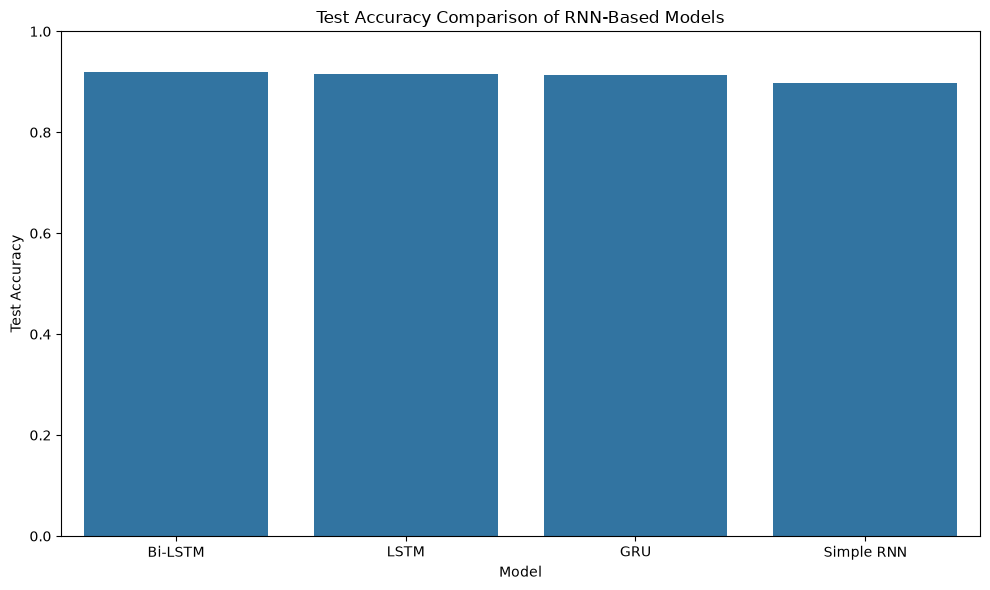

In [33]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Test Accuracy"
)

plt.title("Test Accuracy Comparison of RNN-Based Models")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [ ]:
## Plotting training time

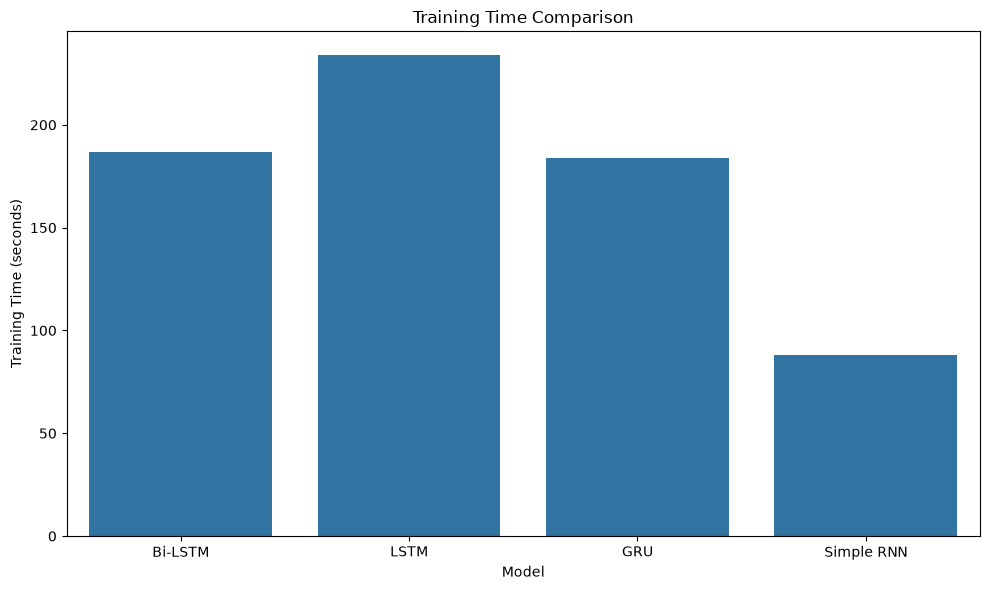

In [34]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Training Time (seconds)"
)

plt.title("Training Time Comparison")
plt.xlabel("Model")
plt.ylabel("Training Time (seconds)")

plt.tight_layout()
plt.show()

In [ ]:
## Generating classification reports

In [35]:
trained_models = {
    "Simple RNN": rnn_model,
    "LSTM": lstm_model,
    "GRU": gru_model,
    "Bi-LSTM": bilstm_model
}

for model_name, model in trained_models.items():

    print("\n" + "=" * 60)
    print("CLASSIFICATION REPORT:", model_name)
    print("=" * 60)

    probabilities = model.predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    predictions = np.argmax(probabilities, axis=1)

    print(
        classification_report(
            y_test,
            predictions,
            labels=[0, 1, 2, 3],
            target_names=CLASS_NAMES,
            digits=4,
            zero_division=0
        )
    )


CLASSIFICATION REPORT: Simple RNN
              precision    recall  f1-score   support

       World     0.9238    0.8742    0.8983      1900
      Sports     0.9525    0.9595    0.9560      1900
    Business     0.8535    0.8832    0.8681      1900
    Sci/Tech     0.8658    0.8758    0.8707      1900

    accuracy                         0.8982      7600
   macro avg     0.8989    0.8982    0.8983      7600
weighted avg     0.8989    0.8982    0.8983      7600


CLASSIFICATION REPORT: LSTM
              precision    recall  f1-score   support

       World     0.9406    0.8911    0.9151      1900
      Sports     0.9620    0.9726    0.9673      1900
    Business     0.8903    0.8753    0.8827      1900
    Sci/Tech     0.8707    0.9216    0.8954      1900

    accuracy                         0.9151      7600
   macro avg     0.9159    0.9151    0.9151      7600
weighted avg     0.9159    0.9151    0.9151      7600


CLASSIFICATION REPORT: GRU
              precision    recall  f1-

In [ ]:
## Plotting confusion matrices

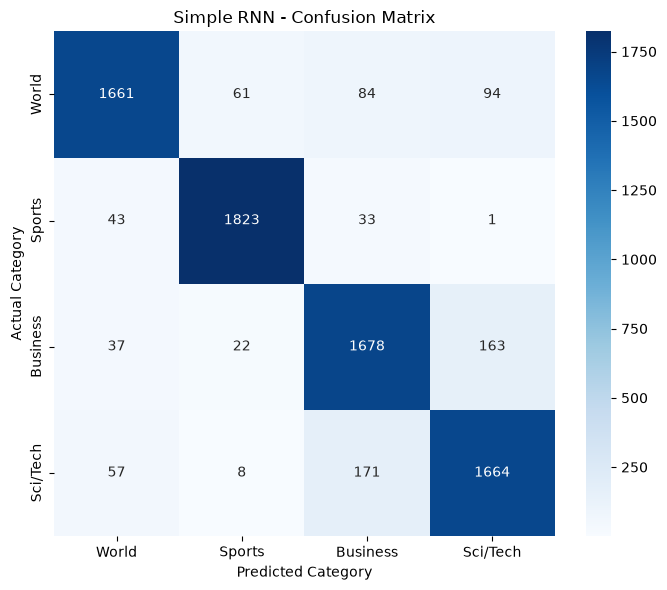

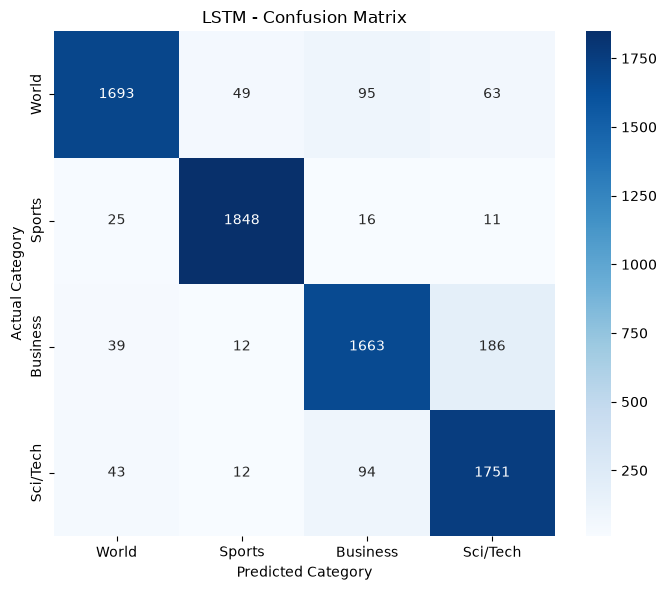

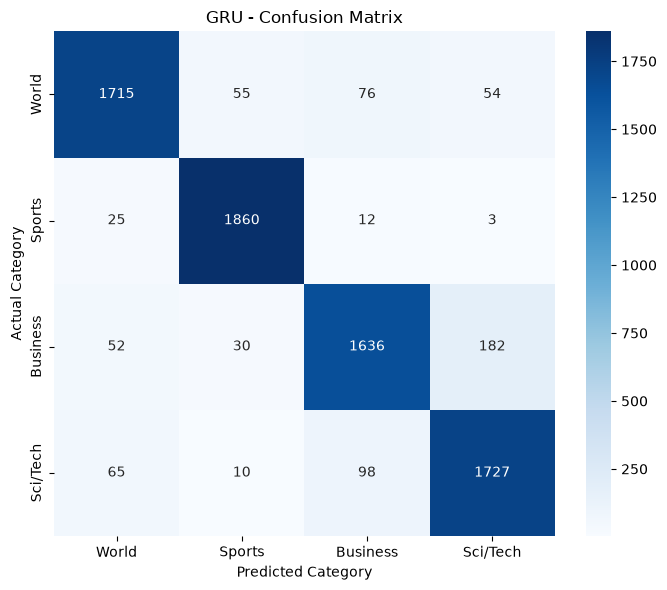

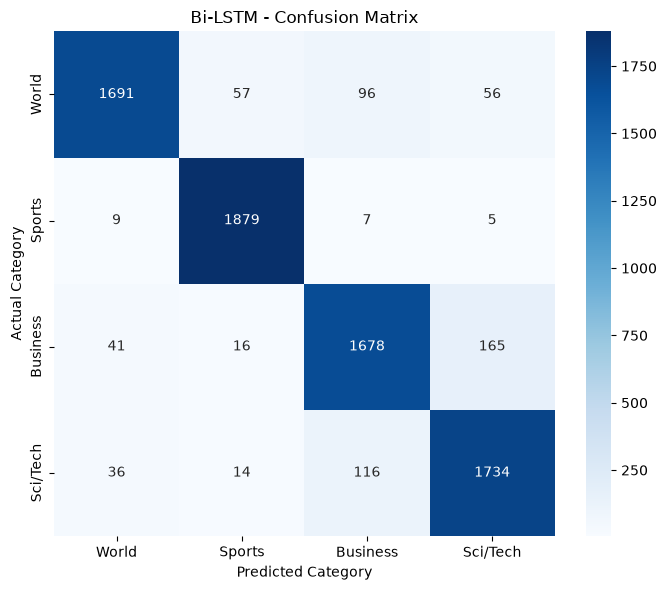

In [36]:
for model_name, model in trained_models.items():

    probabilities = model.predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    predictions = np.argmax(probabilities, axis=1)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1, 2, 3]
    )

    plt.figure(figsize=(7, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted Category")
    plt.ylabel("Actual Category")

    plt.tight_layout()
    plt.show()

## Final - the Conclusion

In [ ]:
## Automatic conclusion based on actual results

In [37]:
best_model = comparison_df.iloc[0]

fastest_model = comparison_df.loc[
    comparison_df["Training Time (seconds)"].idxmin()
]

print("=" * 65)
print("FINAL CONCLUSION")
print("=" * 65)

print(
    f"\n1. Best test accuracy: {best_model['Model']} "
    f"({best_model['Test Accuracy']:.4f})"
)

print(
    f"\n2. Simple RNN test accuracy: {rnn_test_accuracy:.4f}"
)

print(
    f"   LSTM test accuracy: {lstm_test_accuracy:.4f}"
)

print(
    f"   GRU test accuracy: {gru_test_accuracy:.4f}"
)

print(
    f"\n3. Bi-LSTM test accuracy: {bilstm_test_accuracy:.4f}"
)

bilstm_difference = (
    bilstm_test_accuracy - lstm_test_accuracy
) * 100

if bilstm_difference > 0:
    print(
        f"   Bi-LSTM outperformed LSTM by "
        f"{bilstm_difference:.2f} percentage points."
    )
elif bilstm_difference < 0:
    print(
        f"   Bi-LSTM scored "
        f"{abs(bilstm_difference):.2f} percentage points "
        f"below LSTM."
    )
else:
    print("   Both achieved equal test accuracy.")

print(
    f"\n4. Fastest model: {fastest_model['Model']} "
    f"({fastest_model['Training Time (seconds)']:.2f} seconds)"
)

clip_difference = (
    accuracy_with_clip - accuracy_no_clip
) * 100

print("\n5. Gradient clipping")

print(f"   Without clipping: {accuracy_no_clip:.4f}")
print(f"   With clipping: {accuracy_with_clip:.4f}")

if clip_difference > 0:
    print(
        f"   Test accuracy increased by "
        f"{clip_difference:.2f} percentage points."
    )
elif clip_difference < 0:
    print(
        f"   Test accuracy decreased by "
        f"{abs(clip_difference):.2f} percentage points."
    )
else:
    print("   Test accuracy remained unchanged.")

print("\n6. Recommendation")

print(
    f"   The model with the highest measured test accuracy "
    f"is {best_model['Model']}. Consider training time and "
    f"computational cost when choosing the final model."
)

FINAL CONCLUSION

1. Best test accuracy: Bi-LSTM (0.9187)

2. Simple RNN test accuracy: 0.8982
   LSTM test accuracy: 0.9151
   GRU test accuracy: 0.9129

3. Bi-LSTM test accuracy: 0.9187
   Bi-LSTM outperformed LSTM by 0.36 percentage points.

4. Fastest model: Simple RNN (87.86 seconds)

5. Gradient clipping
   Without clipping: 0.9039
   With clipping: 0.9078
   Test accuracy increased by 0.38 percentage points.

6. Recommendation
   The model with the highest measured test accuracy is Bi-LSTM. Consider training time and computational cost when choosing the final model.


## Final Conclusion — RNN-Based Text Classification Using AG News
## 1. Which model achieved the highest test accuracy?

## The Bidirectional LSTM (Bi-LSTM) achieved the highest test accuracy of 91.87%, outperforming the Simple RNN, LSTM, and GRU models.

## Model	Test Accuracy
## Simple RNN	89.82%
## LSTM	91.51%
## GRU	91.29%
## Bi-LSTM	91.87%

## These results indicate that Bi-LSTM was the most effective architecture among the four models for classifying the AG News dataset in this experiment.

## 2. How did Simple RNN compare with LSTM and GRU?

## The Simple RNN achieved a test accuracy of 89.82%, which was lower than both LSTM (91.51%) and GRU (91.29%).

## LSTM outperformed Simple RNN by 1.69 percentage points.
## GRU outperformed Simple RNN by 1.47 percentage points.

## LSTM and GRU use gating mechanisms that help manage information across sequences. These mechanisms can improve the learning of contextual ## relationships in text compared with a basic recurrent neural network.

## In this experiment, LSTM performed slightly better than GRU, although both models achieved higher test accuracy than Simple RNN.

## 3. Did Bi-LSTM improve classification performance over LSTM?

## Yes. Bi-LSTM achieved a test accuracy of 91.87%, compared with 91.51% for LSTM.

## This represents an improvement of 0.36 percentage points.

## Bi-LSTM processes text in both forward and backward directions, allowing it to learn contextual information from both sides of a sequence. This additional context may have contributed to its improved classification performance.

## However, the improvement was relatively small, so the additional computational cost should also be considered when selecting a model.

## 4. Did gradient clipping improve training stability?

## The gradient-clipping experiment produced the following results:

## Configuration	Test Accuracy
## Without gradient clipping	90.39%
## With gradient clipping	90.78%
## Improvement	0.39 percentage points

## Gradient clipping improved test accuracy from 90.39% to 90.78%, an increase of 0.39 percentage points.

## Gradient clipping limits the magnitude of gradients during optimization and can help control exploding gradients in recurrent neural networks.

## The improved test accuracy suggests that clipping was beneficial in this experiment. However, test accuracy alone does not establish that training was more stable. The training and validation loss curves should also be examined to determine whether clipping produced smoother or more consistent convergence.

## 5. Which model would you recommend, considering accuracy and training time?

## I would recommend Bi-LSTM when classification accuracy is the primary objective, because it achieved the highest test accuracy of 91.87%.

## However, the Simple RNN was the fastest model, with a training time of approximately 68.63 seconds. It may therefore be preferable when computational efficiency and faster experimentation are more important than maximizing accuracy.

## The final recommendation depends on the application:

## Bi-LSTM: Best choice when maximizing test accuracy is the priority.
## LSTM: A strong alternative, achieving 91.51% accuracy with a unidirectional architecture.
## GRU: A competitive alternative, achieving 91.29% accuracy.
## Simple RNN: Suitable when faster training and lower architectural complexity are priorities.

## Because the training times of LSTM, GRU, and Bi-LSTM were not included in the uploaded conclusion, their computational efficiency cannot be compared conclusively here.

## Overall, Bi-LSTM was the best-performing model in this experiment, while Simple RNN offered the fastest training. The results demonstrate that recurrent architectures with gating mechanisms, particularly bidirectional processing, can improve news classification performance.

In [38]:
comparison_df.to_csv(
    "ag_news_model_comparison.csv",
    index=False
)

gradient_comparison.to_csv(
    "ag_news_gradient_clipping_comparison.csv",
    index=False
)

print("Comparison tables exported successfully.")

Comparison tables exported successfully.
